# Desafio: Análise de dados de um delivery de refeições
Pandas + NumPy | Rocketseat

## 1. Importações

In [1]:
import pandas as pd
import numpy as np

## 2. Carregamento dos dados

In [2]:
import os

# Usa a pasta dados/ se existir; caso contrário, lê da pasta atual
PASTA = 'dados' if os.path.isdir('dados') else '.'

pedidos = pd.read_csv(f'{PASTA}/pedidos.csv')
pedidos.head()

,ID_Pedido,Data,Cliente_ID,Item,Quantidade,Preco_Unitario
0,1,2023-11-16,222,Torta de Limao,23.0,12.93
1,2,2024-05-25,232,Esfiha,NaN,5.87
2,3,2024-12-20,276,Wrap de Frango,7.0,25.98
3,4,2024-10-17,198,Batata Frita,NaN,11.62
4,5,2023-07-06,385,Esfiha,17.0,6.94


## 3. Análise Exploratória (EDA)

In [3]:
display(pedidos.head())
display(pedidos.tail())
pedidos.info()
display(pedidos.describe())
print(f'Registros: {pedidos.shape[0]} | Colunas: {pedidos.shape[1]}')
print(pedidos.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ID_Pedido       450 non-null    int64  
 1   Data            450 non-null    str    
 2   Cliente_ID      450 non-null    int64  
 3   Item            450 non-null    str    
 4   Quantidade      431 non-null    float64
 5   Preco_Unitario  430 non-null    float64
dtypes: float64(2), int64(2), str(2)
memory usage: 21.2 KB
Registros: 450 | Colunas: 6
ID_Pedido           int64
Data                  str
Cliente_ID          int64
Item                  str
Quantidade        float64
Preco_Unitario    float64
dtype: object


,ID_Pedido,Data,Cliente_ID,Item,Quantidade,Preco_Unitario
0,1,2023-11-16,222,Torta de Limao,23.0,12.93
1,2,2024-05-25,232,Esfiha,NaN,5.87
2,3,2024-12-20,276,Wrap de Frango,7.0,25.98
3,4,2024-10-17,198,Batata Frita,NaN,11.62
4,5,2023-07-06,385,Esfiha,17.0,6.94


,ID_Pedido,Data,Cliente_ID,Item,Quantidade,Preco_Unitario
445,446,2024-02-27,360,Salada Caesar,30.0,27.35
446,447,2025-05-29,228,Salada Caesar,24.0,29.40
447,448,2025-08-23,243,Agua Mineral,26.0,4.54
448,449,2024-08-30,191,Pizza Calabresa,9.0,45.85
449,450,2025-09-29,122,Yakisoba,8.0,31.72


,ID_Pedido,Cliente_ID,Quantidade,Preco_Unitario
count,450.000000,450.000000,431.000000,430.000000
mean,225.500000,245.864444,15.902552,17.856581
std,130.048068,88.360604,9.087931,11.601652
min,1.000000,100.000000,1.000000,4.090000
25%,113.250000,169.000000,8.000000,8.920000
50%,225.500000,241.500000,16.000000,13.095000
75%,337.750000,325.750000,24.000000,27.402500
max,450.000000,399.000000,30.000000,46.070000


## 4. Feature Engineering: Receita_Item

In [4]:
pedidos['Receita_Item'] = pedidos['Quantidade'] * pedidos['Preco_Unitario']
pedidos.head()

,ID_Pedido,Data,Cliente_ID,Item,Quantidade,Preco_Unitario,Receita_Item
0,1,2023-11-16,222,Torta de Limao,23.0,12.93,297.39
1,2,2024-05-25,232,Esfiha,NaN,5.87,NaN
2,3,2024-12-20,276,Wrap de Frango,7.0,25.98,181.86
3,4,2024-10-17,198,Batata Frita,NaN,11.62,NaN
4,5,2023-07-06,385,Esfiha,17.0,6.94,117.98


## 5. Tratamento de valores ausentes

In [5]:
print('Nulos por coluna:')
print(pedidos.isnull().sum())

# Quantidade nula -> média
pedidos['Quantidade'] = pedidos['Quantidade'].fillna(pedidos['Quantidade'].mean())

# Preco_Unitario nulo -> remove a linha
pedidos = pedidos.dropna(subset=['Preco_Unitario']).reset_index(drop=True)

# Recalcula a receita, pois Quantidade/Preco podem ter mudado
pedidos['Receita_Item'] = pedidos['Quantidade'] * pedidos['Preco_Unitario']

print('\nNulos após o tratamento:')
print(pedidos.isnull().sum())

Nulos por coluna:
ID_Pedido          0
Data               0
Cliente_ID         0
Item               0
Quantidade        19
Preco_Unitario    20
Receita_Item      38
dtype: int64

Nulos após o tratamento:
ID_Pedido         0
Data              0
Cliente_ID        0
Item              0
Quantidade        0
Preco_Unitario    0
Receita_Item      0
dtype: int64


## 6. Agregações por Item

In [6]:
por_item = pedidos.groupby('Item').agg(
    Quantidade_Total=('Quantidade', 'sum'),
    Receita_Total=('Receita_Item', 'sum')
)
display(por_item)

print('Top 5 por quantidade:')
display(por_item['Quantidade_Total'].nlargest(5))

print('Top 5 por receita:')
display(por_item['Receita_Total'].nlargest(5))

Top 5 por quantidade:
Top 5 por receita:


,Quantidade_Total,Receita_Total
Item,,
Acai 300ml,402.902552,6502.133503
Agua Mineral,327.902552,1469.399327
Batata Frita,323.902552,3970.357657
Brownie,465.902552,4603.498237
Cafe Expresso,392.000000,2657.710000
Empanada,321.902552,2893.260928
Esfiha,364.707657,2379.656798
Hamburguer,510.805104,11562.230858
Pastel,238.000000,2215.460000


Item
Hamburguer       510.805104
Brownie          465.902552
Acai 300ml       402.902552
Cafe Expresso    392.000000
Sushi 8 pecas    378.902552
Name: Quantidade_Total, dtype: float64

Item
Pizza Calabresa    15903.647958
Pizza Mussarela    14148.690000
Sushi 8 pecas      12085.156473
Hamburguer         11562.230858
Salada Caesar       9927.960000
Name: Receita_Total, dtype: float64

## 7. Análise Temporal
Os dados cobrem 2023 a 2025. Por isso, além do número do mês (pedido no desafio), crio `Ano_Mes` para analisar a evolução sem misturar anos.

In [7]:
pedidos['Data'] = pd.to_datetime(pedidos['Data'])
print('Período:', pedidos['Data'].min().date(), 'a', pedidos['Data'].max().date())

pedidos['Mes'] = pedidos['Data'].dt.month
pedidos['Ano_Mes'] = pedidos['Data'].dt.to_period('M')

# Receita por mês do ano (1-12), somando todos os anos (sazonalidade)
receita_mes = pedidos.groupby('Mes')['Receita_Item'].sum()
display(receita_mes)

Período: 2023-01-02 a 2025-09-29


Mes
1     10102.202668
2     16011.540000
3      7983.080000
4      8549.233503
5     12041.371067
6      9261.508863
7     10592.674084
8     12943.373503
9     14680.497517
10     5405.276984
11     6901.480000
12     8180.353341
Name: Receita_Item, dtype: float64

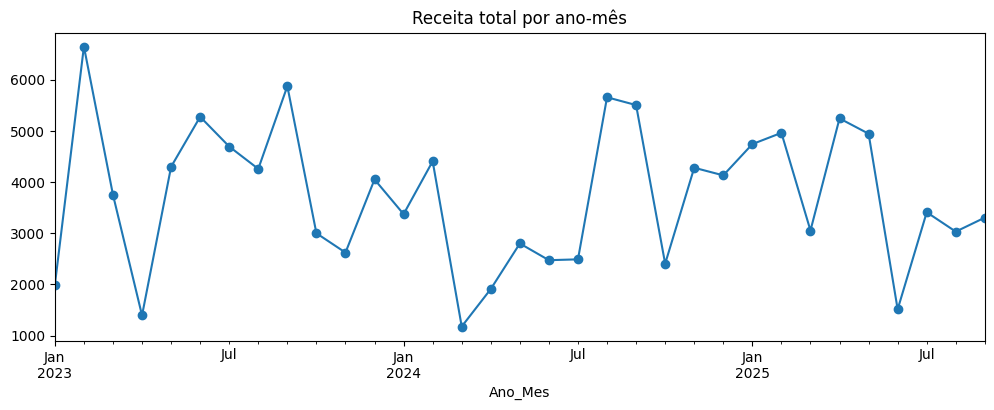

In [8]:
# Evolução real ao longo do tempo (ano-mês)
receita_ano_mes = pedidos.groupby('Ano_Mes')['Receita_Item'].sum()
receita_ano_mes.plot(kind='line', marker='o', figsize=(12, 4), title='Receita total por ano-mês')

In [9]:
# Variação percentual mês a mês
display(receita_ano_mes.pct_change().mul(100).round(2).rename('Variação % vs mês anterior'))
print('Mês de maior receita:', receita_ano_mes.idxmax())
print('Mês de menor receita:', receita_ano_mes.idxmin())

Mês de maior receita: 2023-02
Mês de menor receita: 2024-03


Ano_Mes
2023-01       NaN
2023-02    234.21
2023-03    -43.56
2023-04    -62.79
2023-05    207.87
2023-06     22.71
2023-07    -11.02
2023-08     -9.29
2023-09     37.95
2023-10    -48.91
2023-11    -12.58
2023-12     54.44
2024-01    -16.72
2024-02     30.59
2024-03    -73.24
2024-04     62.14
2024-05     46.51
2024-06    -11.65
2024-07      0.67
2024-08    127.07
2024-09     -2.69
2024-10    -56.29
2024-11     77.89
2024-12     -3.48
2025-01     14.78
2025-02      4.64
2025-03    -38.45
2025-04     71.69
2025-05     -5.69
2025-06    -69.38
2025-07    125.24
2025-08    -11.08
2025-09      9.04
Freq: M, Name: Variação % vs mês anterior, dtype: float64

## 8. Integração de dados (merge)

In [10]:
cardapio = pd.read_csv(f'{PASTA}/cardapio.csv')
display(cardapio.head())

df = pd.merge(pedidos, cardapio, on='Item', how='left')
print('Itens sem categoria:', df['Categoria'].isnull().sum())

receita_categoria = df.groupby('Categoria')['Receita_Item'].sum().sort_values(ascending=False)
display(receita_categoria)
print('Categoria que mais gera receita:', receita_categoria.idxmax())

Itens sem categoria: 0
Categoria que mais gera receita: Salgados


,Item,Categoria,Preco_Base
0,Hamburguer,Salgados,22.9
1,Batata Frita,Salgados,12.5
2,Pizza Mussarela,Salgados,39.9
3,Pizza Calabresa,Salgados,42.9
4,Salada Caesar,Saudaveis,28.0


Categoria
Salgados     53073.304200
Doces        22293.944060
Oriental     21599.796473
Saudaveis    16539.040000
Bebidas       9146.506798
Name: Receita_Item, dtype: float64

## 9. Filtros e consultas

In [11]:
salgados = df[(df['Categoria'] == 'Salgados') & (df['Quantidade'] > 10)]
display(salgados)

,ID_Pedido,Data,Cliente_ID,Item,Quantidade,Preco_Unitario,Receita_Item,Mes,Ano_Mes,Categoria,Preco_Base
1,2,2024-05-25,232,Esfiha,15.902552,5.87,93.347981,5,2024-05,Salgados,6.5
3,4,2024-10-17,198,Batata Frita,15.902552,11.62,184.787657,10,2024-10,Salgados,12.5
4,5,2023-07-06,385,Esfiha,17.000000,6.94,117.980000,7,2023-07,Salgados,6.5
5,6,2023-02-04,260,Empanada,16.000000,9.48,151.680000,2,2023-02,Salgados,8.9
14,15,2023-02-03,103,Batata Frita,14.000000,13.13,183.820000,2,2023-02,Salgados,12.5
...,...,...,...,...,...,...,...,...,...,...,...
404,423,2023-02-05,252,Pizza Calabresa,16.000000,41.75,668.000000,2,2023-02,Salgados,42.9
409,428,2023-07-11,278,Pastel,18.000000,9.30,167.400000,7,2023-07,Salgados,9.5
415,434,2024-07-17,249,Esfiha,26.000000,5.96,154.960000,7,2024-07,Salgados,6.5
422,442,2023-01-02,261,Esfiha,15.902552,6.83,108.614432,1,2023-01,Salgados,6.5


## 10. KPIs com NumPy

In [12]:
receita_total = np.sum(df['Receita_Item'])
total_itens = np.sum(df['Quantidade'])
n_pedidos = df['ID_Pedido'].nunique()  # número de pedidos únicos
ticket_medio = receita_total / n_pedidos

print(f'Receita Total:        R$ {receita_total:,.2f}')
print(f'Total de Itens:       {total_itens:,.0f}')
print(f'Ticket Médio:         R$ {ticket_medio:,.2f}')

Receita Total:        R$ 122,652.59
Total de Itens:       6,833
Ticket Médio:         R$ 285.24


### Desafio extra: percentis

In [13]:
for col in ['Preco_Unitario', 'Quantidade']:
    p25, p50, p75 = np.percentile(df[col], [25, 50, 75])
    print(f'{col}: P25={p25:.2f} | P50={p50:.2f} | P75={p75:.2f}')

Preco_Unitario: P25=8.92 | P50=13.10 | P75=27.40
Quantidade: P25=8.00 | P50=16.00 | P75=24.00


## Conclusões

- **Salgados dominam o negócio:** respondem por cerca de 43% da receita total (R$ 53,1 mil de R$ 122,7 mil), bem à frente de Doces e Oriental. Bebidas ficam na última posição (~7%).
- **Volume não é receita:** o Hambúrguer é o item mais vendido em quantidade, mas as pizzas (Calabresa e Mussarela) lideram em receita por terem preço unitário bem maior. Já o Sushi aparece nos dois rankings, entre os cinco primeiros.
- **Sem tendência clara de crescimento:** a receita mensal oscila bastante de um mês para o outro (de 2023-01 a 2025-09), com pico em 2023-02 e menor valor em 2024-03. Somando os anos, fevereiro e setembro são os meses mais fortes e outubro o mais fraco.
- **Ticket médio de R$ 285,24:** calculado sobre 430 pedidos, depois de remover as linhas sem preço unitário.
- **Observação metodológica:** os nulos de `Quantidade` foram preenchidos com a média (~15,9), como pede o desafio, o que gera quantidades fracionadas em alguns itens.